## 4. 딥러닝 기반 Edge AI 객체 탐지 시스템

> 전체 노트북 파일에서 과제 범위에 해당되는 코드 셀과 마크다운 셀을 가져와 포함했습니다.

포함된 내용
- IoU, NMS 구현

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import skimage.data

In [2]:
def draw_bbox(img, coord1, coord2, color, thickness=3, txt=""):
    _, txt_h = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.8, 2)[0]
    cv2.rectangle(img, coord1, coord2, color, thickness)
    cv2.putText(img, txt, (coord1[0], coord1[1]-txt_h+15), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

### B. Intersection over Union (IoU)

Intersection over Union (IoU):
* 두 Bounding Box가 얼마나 겹치는지를 나타내는 값
* (교집합 면적) / (합집합 면적)
* 값의 범위: 0 ≤ IoU ≤ 1
  * IoU = 0:  전혀 겹치지 않음
  * IoU = 1:  두 BBox가 완전히 동일


```python
bbox_a = (xa_1, ya_1, xa_2, ya_2)
bbox_b = (xb_1, yb_1, xb_2, yb_2)
```

두개의 BBox를 위와 같이 표현한다면, 좌표들을 사용해 교집합 박스의 좌표를 구할 수 있습니다.

```python
intersection_x1 = max(xa_1, xb_1)
intersection_y1 = max(ya_1, yb_1)
intersection_x2 = min(xa_2, xb_2)
intersection_y2 = min(ya_2, yb_2)
```

<br>
그 다음, 교집합 박스의 너비와 높이를 계산합니다.

```python
w = max(0, intersection_x2 - intersection_x1)
h = max(0, intersection_y2 - intersection_y1)
```

겹치는 영역이 없다면 `intersection2 - intersection1`의 값이 음수가 되어 너비와 높이가 0이 됩니다.

<br>
교집합의 넓이를 계산했다면, 최종적으로 합집합의 넓이까지 계산하여 IoU 값을 구할 수 있습니다.

IoU 계산 함수를 구현해봅시다.

In [ ]:
# TODO: 1) BBox 좌표를 (x,y,w,h)에서 (x1,y1,x2,y2)로 변환하는 함수 정의
# TODO: 2) IoU 계산 함수 정의

def convert_bbox_coord(bbox):
    x, y, w, h = bbox

    x1 = x
    x2 = x + w
    y1 = y
    y2 = y + h

    return (x1, y1, x2, y2)

def calculate_iou(bbox_a, bbox_b, input_format="xywh"):

    if input_format == "xywh": # 실습 노트북에서 입력으로 xywh, xyxy 두 형식이 들어올 수 있어 아래쪽 실습에서의 코드 재사용을 위해 if문 분기 처리했습니다.
        xa, ya, wa, ha = bbox_a
        xb, yb, wb, hb = bbox_b

        xa_1, ya_1, xa_2, ya_2 = convert_bbox_coord(bbox_a)
        xb_1, yb_1, xb_2, yb_2 = convert_bbox_coord(bbox_b)

    elif input_format == "xyxy":
        xa_1, ya_1, xa_2, ya_2 = bbox_a
        xb_1, yb_1, xb_2, yb_2 = bbox_b

        wa = xa_2 - xa_1
        ha = ya_2 - ya_1
        wb = xb_2 - xb_1
        hb = yb_2 - yb_1
    else:
        print("형식이 올바르게 지정되지 않음")
        return None

    intersection_x1 = max(xa_1, xb_1)
    intersection_y1 = max(ya_1, yb_1)
    intersection_x2 = min(xa_2, xb_2)
    intersection_y2 = min(ya_2, yb_2)

    w = max(0, intersection_x2 - intersection_x1)
    h = max(0, intersection_y2 - intersection_y1)

    intersection_area = w * h
    union_area = wa * ha + wb * hb - intersection_area

    if union_area == 0:
        return 0

    # TODO: ZeroDivisionError 주의
    return intersection_area / union_area

이제 3개의 이미지에서 IoU를 계산해봅시다.

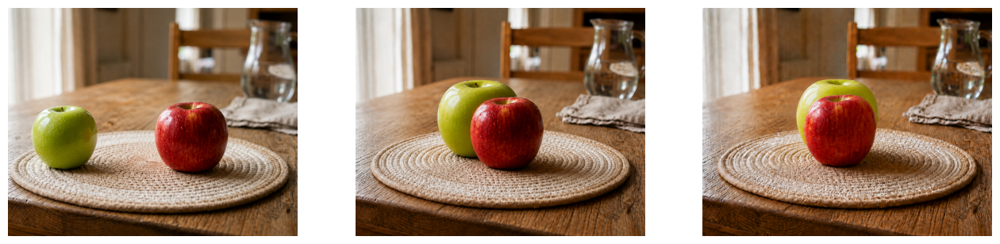

In [4]:
apples1 = cv2.imread("../src/images/two_apples1.png")
apples2 = cv2.imread("../src/images/two_apples2.png")
apples3 = cv2.imread("../src/images/two_apples3.png")
apples1_rgb = cv2.cvtColor(apples1, cv2.COLOR_BGR2RGB)
apples2_rgb = cv2.cvtColor(apples2, cv2.COLOR_BGR2RGB)
apples3_rgb = cv2.cvtColor(apples3, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16,6))

plt.subplot(1,3,1), plt.imshow(apples1_rgb)
plt.subplot(1,3,2), plt.imshow(apples2_rgb)
plt.subplot(1,3,3), plt.imshow(apples3_rgb)

for ax in plt.gcf().axes:
    ax.axis("off")

In [5]:
def get_contour(img_bgr):
    red_lower1 = np.array([0, 100, 50])
    red_upper1 = np.array([10, 255, 255])
    red_lower2 = np.array([170, 100, 50])
    red_upper2 = np.array([180, 255, 255])
    green_lower = np.array([25, 10, 30])
    green_upper = np.array([100, 255, 255])

    img_blr = cv2.GaussianBlur(img_bgr, (7, 7), 0)
    blr_hsv = cv2.cvtColor(img_blr, cv2.COLOR_BGR2HSV)

    red_mask1 = cv2.inRange(blr_hsv, red_lower1, red_upper1)
    red_mask2 = cv2.inRange(blr_hsv, red_lower2, red_upper2)
    red_mask = cv2.bitwise_or(red_mask1, red_mask2)
    grn_mask = cv2.inRange(blr_hsv, green_lower, green_upper)

    contours_red, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours_grn, _ = cv2.findContours(grn_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    cntr_red, cntr_grn = None, None

    if len(contours_red) > 0:
        cntr_red = max(contours_red, key=cv2.contourArea)
    if len(contours_grn) > 0:
        cntr_grn = max(contours_grn, key=cv2.contourArea)

    return cntr_red, cntr_grn

In [6]:
apples1 = cv2.imread("../src/images/two_apples1.png")
apples2 = cv2.imread("../src/images/two_apples2.png")
apples3 = cv2.imread("../src/images/two_apples3.png")

apples1_rgb = cv2.cvtColor(apples1, cv2.COLOR_BGR2RGB)
apples2_rgb = cv2.cvtColor(apples2, cv2.COLOR_BGR2RGB)
apples3_rgb = cv2.cvtColor(apples3, cv2.COLOR_BGR2RGB)

cntr_red1, cntr_grn1 = get_contour(apples1)
cntr_red2, cntr_grn2 = get_contour(apples2)
cntr_red3, cntr_grn3 = get_contour(apples3)

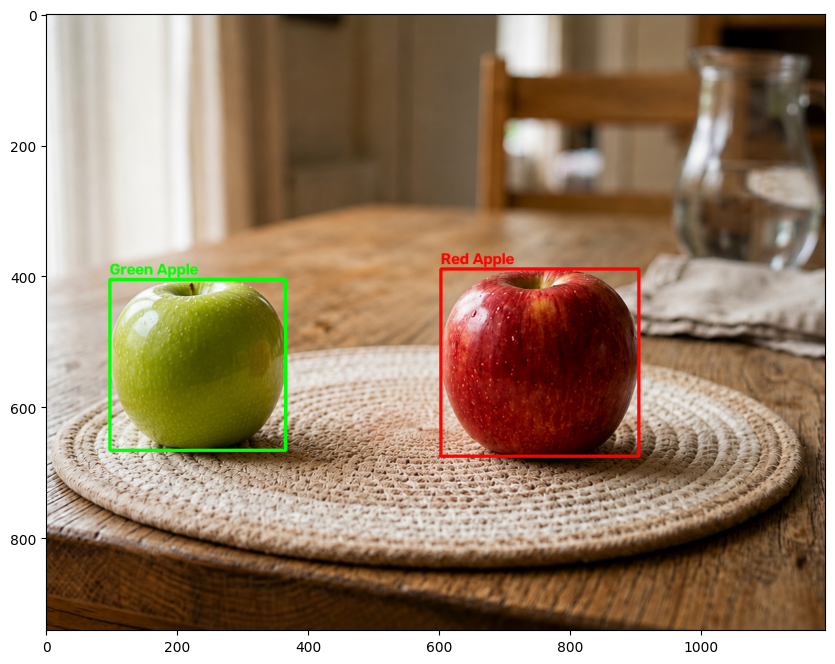

In [7]:
bbox1 = cv2.boundingRect(cntr_red1)
bbox2 = cv2.boundingRect(cntr_grn1)

x_r, y_r, w_r, h_r = bbox1
x_g, y_g, w_g, h_g = bbox2

x_r1, y_r1 = x_r, y_r
x_r2, y_r2 = x_r+w_r, y_r+h_r
x_g1, y_g1 = x_g, y_g
x_g2, y_g2 = x_g+w_g, y_g+h_g

draw_bbox(apples1_rgb, (x_r1, y_r1), (x_r2, y_r2), (255, 0, 0), txt="Red Apple")
draw_bbox(apples1_rgb, (x_g1, y_g1), (x_g2, y_g2), (0, 255, 0), txt="Green Apple")

plt.figure(figsize=(12,8))
plt.imshow(apples1_rgb);

In [8]:
iou1 = calculate_iou(convert_bbox_coord(bbox1), convert_bbox_coord(bbox2), input_format="xyxy")
print(iou1)

0.0


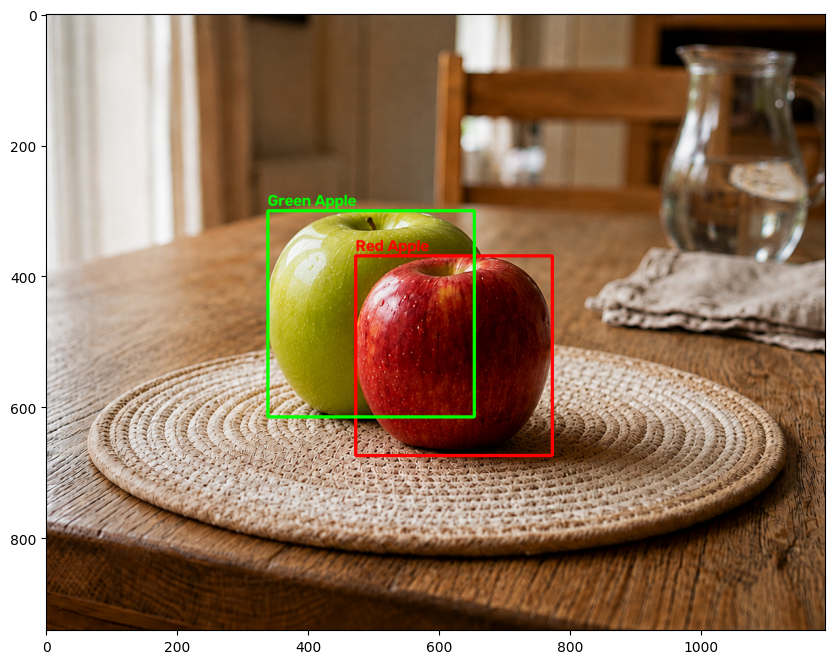

In [9]:
bbox1 = cv2.boundingRect(cntr_red2)
bbox2 = cv2.boundingRect(cntr_grn2)

x_r, y_r, w_r, h_r = bbox1
x_g, y_g, w_g, h_g = bbox2

x_r1, y_r1 = x_r, y_r
x_r2, y_r2 = x_r+w_r, y_r+h_r
x_g1, y_g1 = x_g, y_g
x_g2, y_g2 = x_g+w_g, y_g+h_g

draw_bbox(apples2_rgb, (x_r1, y_r1), (x_r2, y_r2), (255, 0, 0), txt="Red Apple")
draw_bbox(apples2_rgb, (x_g1, y_g1), (x_g2, y_g2), (0, 255, 0), txt="Green Apple")

plt.figure(figsize=(12,8))
plt.imshow(apples2_rgb);

In [10]:
iou2 = calculate_iou(convert_bbox_coord(bbox1), convert_bbox_coord(bbox2), input_format="xyxy")
print(iou2)

0.3045574867133154


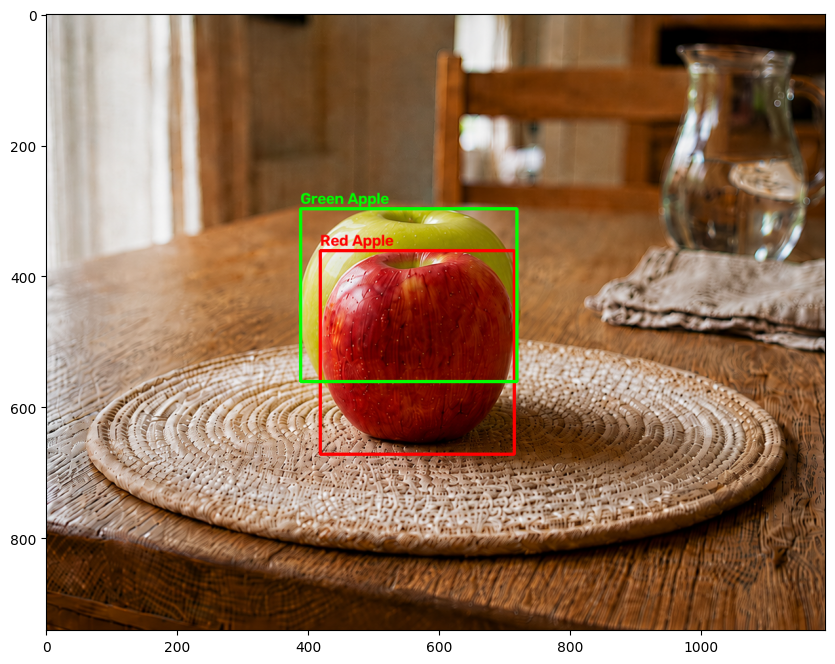

In [11]:
bbox1 = cv2.boundingRect(cntr_red3)
bbox2 = cv2.boundingRect(cntr_grn3)

x_r, y_r, w_r, h_r = bbox1
x_g, y_g, w_g, h_g = bbox2

x_r1, y_r1 = x_r, y_r
x_r2, y_r2 = x_r+w_r, y_r+h_r
x_g1, y_g1 = x_g, y_g
x_g2, y_g2 = x_g+w_g, y_g+h_g

draw_bbox(apples3_rgb, (x_r1, y_r1), (x_r2, y_r2), (255, 0, 0), txt="Red Apple")
draw_bbox(apples3_rgb, (x_g1, y_g1), (x_g2, y_g2), (0, 255, 0), txt="Green Apple")

plt.figure(figsize=(12,8))
plt.imshow(apples3_rgb);

In [12]:
iou3 = calculate_iou(convert_bbox_coord(bbox1), convert_bbox_coord(bbox2), input_format="xyxy")
print(iou3)

0.4934320197372808


이제 3가지 이미지의 IoU를 비교해봅시다.

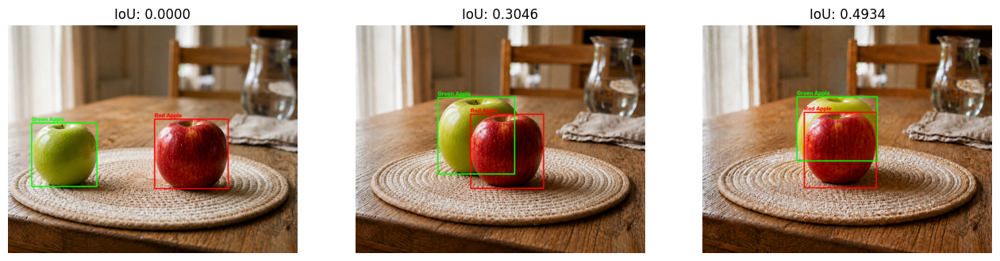

In [13]:
plt.figure(figsize=(16,6))

plt.subplot(1,3,1), plt.imshow(apples1_rgb), plt.title(f"IoU: {iou1:.4f}")
plt.subplot(1,3,2), plt.imshow(apples2_rgb), plt.title(f"IoU: {iou2:.4f}")
plt.subplot(1,3,3), plt.imshow(apples3_rgb), plt.title(f"IoU: {iou3:.4f}")

for ax in plt.gcf().axes:
    ax.axis("off")

---

### C. Non-Maximum Suppression (NMS)

비최대 억제 (NMS):
* 동일한 객체에 대해 여러 개의 Bounding Box가 높은 신뢰도로 예측될 수 있음
* 중복 Bounding Box를 제거하는 알고리즘
* Confidence Score와 IoU 기준으로 Bounding Box 선택
* 중복 제거 과정을 반복하여 객체마다 하나의 대표 Bounding Box만 남김

NMS 과정 (2~6번):
1. 신뢰도가 너무 낮은 BBox 제거 (Confidence Thresholding)
2. Confidence가 가장 높은 BBox 선택
3. 선택한 BBox와 다른 박스들의 IoU 계산
4. IoU가 임계값보다 높은 박스 제거 (IoU Thresholding)
5. 다음으로 Confidence가 가장 높은 BBox 선택
6. 3, 4, 5번 반복


NMS 알고리즘을 구현하기 앞서, 우선 랜덤으로 BBox를 생성해봅시다.

In [14]:
from random import randint, gauss

def random_bbox(img, min_w=100, min_h=400, max_w=600, max_h=600):
    img_h, img_w = img.shape[:2]

    w = randint(min_w, min(max_w, img_w))
    h = randint(min_h, min(max_h, img_h))

    x1 = randint(0, img_w - w)
    y1 = randint(0, img_h - h)

    return x1, y1, x1 + w, y1 + h

def random_conf():
    return min(1.0, max(0.0, gauss(0.6, 0.1)))

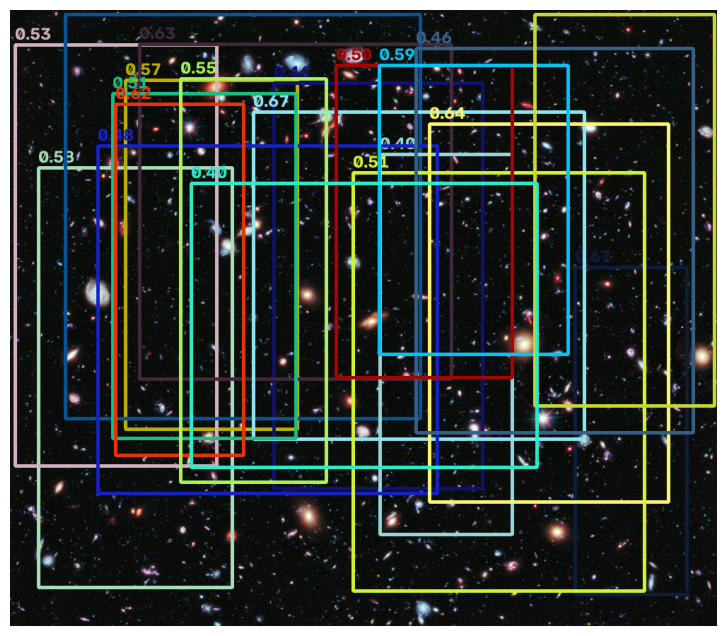

In [15]:
hubble = skimage.data.hubble_deep_field()

N = 20

boxes = []
scores = []

for i in range(N):
    boxes.append(random_bbox(hubble))
    scores.append(random_conf())

for i, box in enumerate(boxes):
    draw_bbox(
        hubble,
        (box[0], box[1]),
        (box[2], box[3]),
        (randint(0,255), randint(0,255), randint(0,255)),
        txt=f"{scores[i]:.2f}"
    )

plt.figure(figsize=(10,8))
plt.imshow(hubble)
plt.axis("off");

이제 이 난잡한 BBox 정글을 NMS로 정리해보도록 합시다.

In [16]:
# TODO: Confidence Thresholding 함수 정의
# TODO: Confidence Score가 특정 임계값보다 낮으면 해당 BBox 제거

def prune_low_conf(boxes, scores, conf_threshold=0.5):
    """
    Confidence Thresholding 적용

    Parameters
    ----------
    boxes : list
        Bounding Box 목록
        각 박스는 (x1, y1, x2, y2) 형식

    scores : list
        각 Bounding Box의 Confidence Score

    conf_threshold : float
        Bounding Box를 유지하기 위한 최소 Confidence Score

    Returns
    -------
    pruned_boxes : list
        Confidence Score가 임계값 이상인 Bounding Box 목록

    pruned_scores : list
        Confidence Score가 임계값 이상인 Bounding Box의 Confidence Score 목록
    """

    pruned_boxes = []
    pruned_scores = []


    for box, score in zip(boxes, scores):
        if score >= conf_threshold:
            pruned_boxes.append(box)
            pruned_scores.append(score)
    
    return pruned_boxes, pruned_scores




In [ ]:
# TODO: NMS 함수 정의
# TODO: np.sort() 함수를 사용하면 1차원 배열을 정렬
# TODO: np.argsort() 함수를 사용하면 1차원 배열의 정렬된 인덱스를 반환

def apply_nms(boxes, scores, iou_threshold=0.5):
    """
    NMS 적용

    Parameters
    ----------
    boxes : list
        Bounding Box 목록
        각 박스는 (x1, y1, x2, y2) 형식

    scores : list
        각 Bounding Box의 Confidence Score

    iou_threshold : float
        중복 Bounding Box를 제거할 IoU 기준값

    Returns
    -------
    nms_boxes : list
        NMS 적용 후 유지된 Bounding Box 목록

    nms_scores : list
        NMS 적용 후 유지된 Bounding Box의 Confidence Score 목록
    """

    order = np.argsort(scores)[::-1]
    keep = []

    while len(order) > 0:
        best = order[0] 
        keep.append(best)

        remaining = [] # 살아남은 후보 인덱스를 담을 리스트

        for i in order[1:]:
            iou = calculate_iou(boxes[best], boxes[i], input_format="xyxy")

            if iou <= iou_threshold:
                remaining.append(i)

        order = remaining

    nms_boxes = [boxes[i] for i in keep]
    nms_scores = [scores[i] for i in keep]

    return nms_boxes, nms_scores

이제 Confidence Thresholding과 NMS를 적용해봅시다.

In [18]:
print(len(boxes), len(scores))

new_boxes, new_scores = prune_low_conf(boxes, scores)
new_boxes, new_scores = apply_nms(new_boxes, new_scores, iou_threshold=0.2)

print(len(new_boxes), len(new_scores))

20 20
4 4


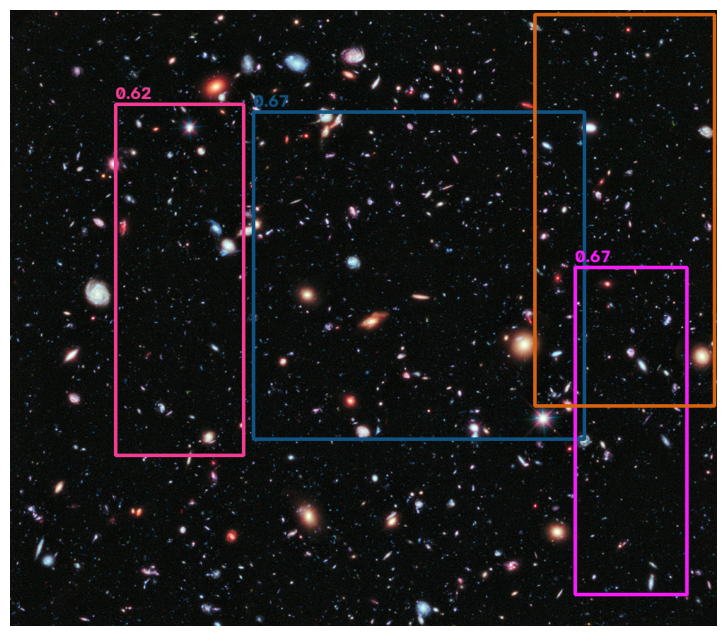

In [19]:
hubble = skimage.data.hubble_deep_field()

for i, box in enumerate(new_boxes):
    draw_bbox(
        hubble,
        (box[0], box[1]),
        (box[2], box[3]),
        (randint(0,255), randint(0,255), randint(0,255)),
        txt=f"{new_scores[i]:.2f}"
    )

plt.figure(figsize=(10,8))
plt.imshow(hubble)
plt.axis("off");

확실히 중복된 Bounding Box는 제거된 모습을 확인할 수 있습니다.

여전히 중복되어 있는 BBox들은, 겹친 영역의 면적이 작거나 합집합의 면적이 넓어 교집합:합집합 비율이 임계값보다 낮은 경우입니다.

지금까지 NMS 알고리즘의 동작 원리를 이해하기 위해 직접 코드로 구현해 보았습니다.

OpenCV에서도 동일한 역할을 하는 내장 함수 `cv2.dnn.NMSBoxes()`가 제공됩니다.

OpenCV 함수를 사용해 같은 과정을 반복해 보고 결과를 비교해봅시다.

In [20]:
def apply_nms_cv2(boxes, scores, conf_threshold=0.5, iou_threshold=0.5):
    """
    OpenCV의 cv2.dnn.NMSBoxes()를 이용해 NMS 적용

    Parameters
    ----------
    boxes : list
        Bounding Box 목록
        각 박스는 (x1, y1, x2, y2) 형식

    scores : list
        각 Bounding Box의 Confidence Score

    conf_threshold : float
        Bounding Box를 유지하기 위한 최소 Confidence Score

    iou_threshold : float
        중복 Bounding Box를 제거할 IoU 기준값

    Returns
    -------
    nms_boxes : list
        NMS 적용 후 유지된 Bounding Box 목록
        각 박스는 기존과 동일한 (x1, y1, x2, y2) 형식

    nms_scores : list
        NMS 적용 후 유지된 Bounding Box의 Confidence Score
    """

    if len(boxes) == 0:
        return [], []

    # cv2.dnn.NMSBoxes()는 (x, y, width, height) 형식을 사용
    boxes_xywh = []

    for box in boxes:
        x1, y1, x2, y2 = box

        width = x2 - x1
        height = y2 - y1

        boxes_xywh.append([int(x1), int(y1), int(width), int(height)])

    # OpenCV NMS 적용하여 BBox 제거 후 남은 BBox의 인덱스
    keep_indices = cv2.dnn.NMSBoxes(
        bboxes=boxes_xywh,
        scores=scores,
        score_threshold=conf_threshold,
        nms_threshold=iou_threshold,
    )

    # 1차원 리스트로 변환
    keep_indices = np.array(keep_indices).reshape(-1).tolist()

    # 원래 xyxy 형식의 박스에서 선택
    nms_boxes = [boxes[index] for index in keep_indices]
    nms_scores = [scores[index] for index in keep_indices]

    return nms_boxes, nms_scores

다시 NMS 적용 전 이미지를 확인합시다.

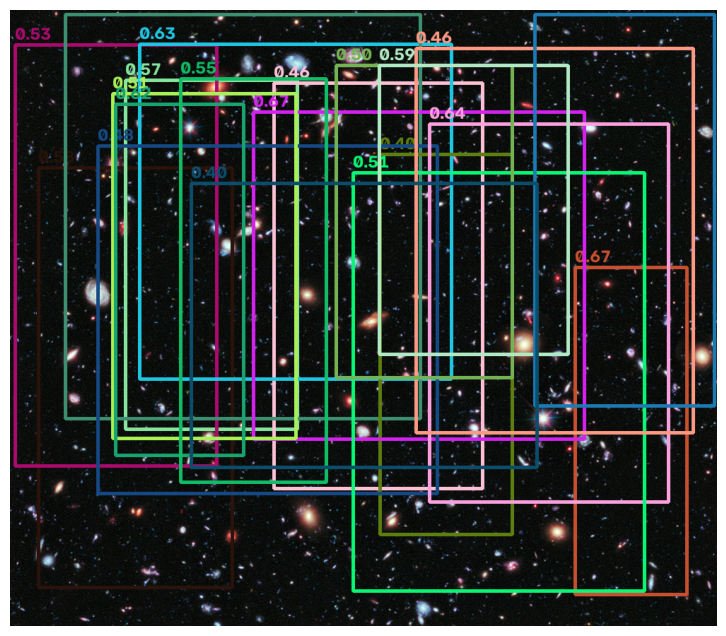

In [21]:
hubble = skimage.data.hubble_deep_field()

for i, box in enumerate(boxes):
    draw_bbox(
        hubble,
        (box[0], box[1]),
        (box[2], box[3]),
        (randint(0,255), randint(0,255), randint(0,255)),
        txt=f"{scores[i]:.2f}"
    )

plt.figure(figsize=(10,8))
plt.imshow(hubble)
plt.axis("off");

OpenCV의 NMS 적용:

In [22]:
print(len(boxes), len(scores))

cv2_new_boxes, cv2_new_scores = apply_nms_cv2(boxes, scores, iou_threshold=0.2)

print(len(cv2_new_boxes), len(cv2_new_scores))

20 20
4 4


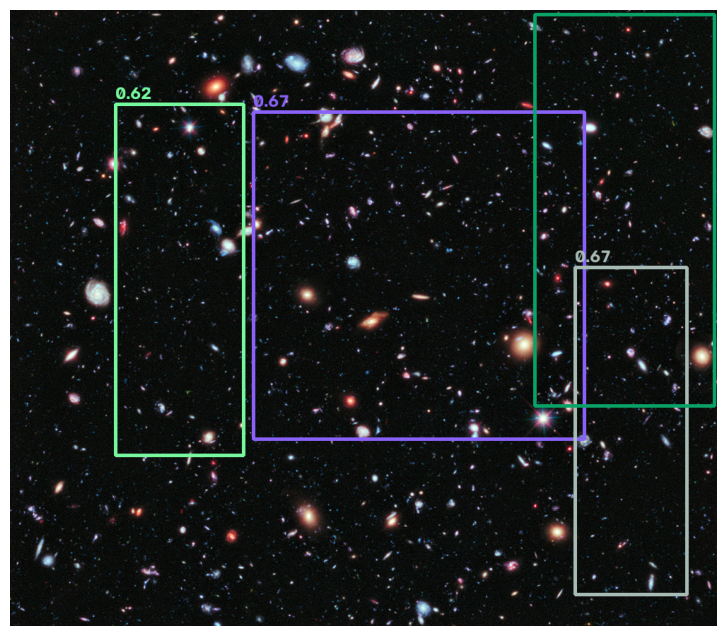

In [23]:
hubble_cv2_nms = skimage.data.hubble_deep_field()

for i, box in enumerate(cv2_new_boxes):
    draw_bbox(
        hubble_cv2_nms,
        (box[0], box[1]),
        (box[2], box[3]),
        (randint(0,255), randint(0,255), randint(0,255)),
        txt=f"{cv2_new_scores[i]:.2f}"
    )

plt.figure(figsize=(10,8))
plt.imshow(hubble_cv2_nms)
plt.axis("off");

직접 구현한 NMS와 OpenCV 내장 NMS의 결과를 비교해봅시다.

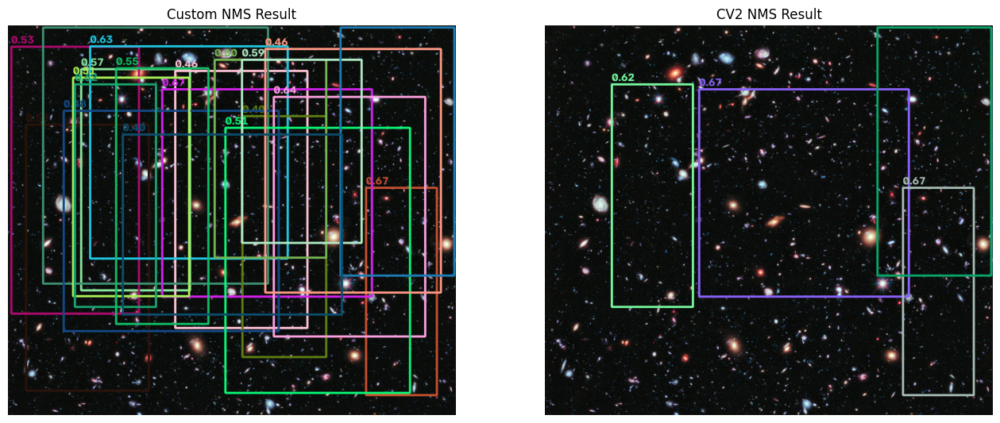

In [24]:
plt.figure(figsize=(16,10))

plt.subplot(1,2,1), plt.imshow(hubble), plt.title("Custom NMS Result")
plt.subplot(1,2,2), plt.imshow(hubble_cv2_nms), plt.title("CV2 NMS Result")

for ax in plt.gcf().axes:
    ax.axis("off")

직접 구현한 결과와 정확히 일치하는 것을 확인할 수 있습니다.

OpenCV 내장 함수를 사용하면 간단하게 NMS를 적용할 수 있지만, 알고리즘을 직접 구현해 봄으로써 그 내부 동작 원리를 깊이 있게 이해할 수 있습니다.